[Material used to generate Fig.7]

Visualize the relative error of the closed-form approximation and the MODFLOW formula. The error is computed for a distribution of input variables.

The correlation between relative error and the input variables is also computed.

Data is generated with the script exp4.py

In [1]:
# Standard imports
import pathlib
from itertools import product

# Third party imports
import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Internal imports

In [2]:
# set plot style
%matplotlib widget
plt.style.use('plot_style.txt')

# output path for figures 
output_path = pathlib.Path("/home/jonas/shared/Work/SSeep2026/Figures")

### Relative error distributions

Three stream configurations are considered:
- small (1cm < wc < 10cm and 2cm < stage < 50cm)
- medium (10cm < wc < 50cm and 50cm < stage < 2m)
- large (50cm < wc < 2m and 2m < stage < 6m)

For each configuration the relative error from MODFLOW, q_approx_full and the
max of q_approx are computed for 1000 random profiles. Both vGM and BCB, and 
SAND and LOAM_SAND are considered.

data is generated with exp4.py and loaded here

In [3]:
config = ['large', 'medium', 'small']
aq_para = ['vGM', 'BCB']
texture = ['SAND', 'SAND_LOAM']

data = {}
for v1, v2, v3 in product(config, aq_para, texture):
    df = pd.read_csv(f'../data/exp4_{v1}_{v2}_{v3}/rel_error.csv', index_col=0)

    idx1 = np.logical_and(df['unsaturated'], df['clogged'])
    idx2 = np.logical_and(~df['van_cap_zone'], df['increasing'])
    idx = np.logical_and(idx1, idx2)
    df = df.loc[idx]

    data[v1, v2, v3, 'mf'] = df['rel_err_mf'].values
    data[v1, v2, v3, 'dis'] = df['rel_err_dis'].values
    data[v1, v2, v3, 'max'] = df['rel_err_max'].values

plot relative errors

/tmp/ipykernel_23767/2295251019.py:136: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


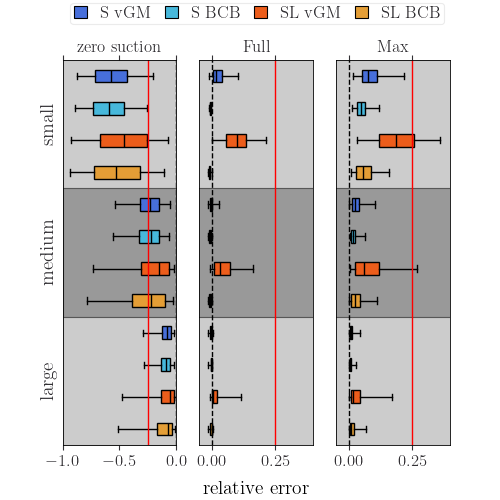

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(5, 5))
for ax in axs:
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.tick_params(top=True, right=True)
    ax.set(xscale='linear', yscale='linear')
    ax.minorticks_off()


# set colors 
c_S_vGM = "#476fdbff"
c_S_BCB = "#47b8dbff"
c_SL_vGM = "#ec5d1bff"
c_SL_BCB = "#e49e36ff"



# box plots
y = np.array([2, 4, 6])
dy = 0.5

# MODFLOW
_data = [data[v1, 'vGM', 'SAND', 'mf'] for v1 in config]
bp = axs[0].boxplot(_data, positions=y + 1.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_vGM)

_data = [data[v1, 'BCB', 'SAND', 'mf'] for v1 in config]
bp = axs[0].boxplot(_data, positions=y + 0.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_BCB)

_data = [data[v1, 'vGM', 'SAND_LOAM', 'mf'] for v1 in config]
bp = axs[0].boxplot(_data, positions=y - 0.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_SL_vGM)

_data = [data[v1, 'BCB', 'SAND_LOAM', 'mf'] for v1 in config]
bp = axs[0].boxplot(_data, positions=y - 1.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_SL_BCB)

# fully disconnected
_data = [data[v1, 'vGM', 'SAND', 'dis'] for v1 in config]
bp = axs[1].boxplot(_data, positions=y + 1.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_vGM)

_data = [data[v1, 'BCB', 'SAND', 'dis'] for v1 in config]
bp = axs[1].boxplot(_data, positions=y + 0.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_BCB)

_data = [data[v1, 'vGM', 'SAND_LOAM', 'dis'] for v1 in config]
bp = axs[1].boxplot(_data, positions=y - 0.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_SL_vGM)

_data = [data[v1, 'BCB', 'SAND_LOAM', 'dis'] for v1 in config]
bp = axs[1].boxplot(_data, positions=y - 1.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_SL_BCB)

# maximal rel. error
_data = [data[v1, 'vGM', 'SAND', 'max'] for v1 in config]
bp = axs[2].boxplot(_data, positions=y + 1.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_vGM)

_data = [data[v1, 'BCB', 'SAND', 'max'] for v1 in config]
bp = axs[2].boxplot(_data, positions=y + 0.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_BCB)

_data = [data[v1, 'vGM', 'SAND_LOAM', 'max'] for v1 in config]
bp = axs[2].boxplot(_data, positions=y - 0.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_SL_vGM)

_data = [data[v1, 'BCB', 'SAND_LOAM', 'max'] for v1 in config]
bp = axs[2].boxplot(_data, positions=y - 1.5 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_SL_BCB)



# layout
for ax in axs:
    ax.axvline(0, ls='--', c='k', lw=1)
    ax.set_yticks([], labels=[])
    ax.set_ylim(ymin=1, ymax=7)
    ax.fill_between([-1, 1], y1=[1, 1], y2=[3, 3], color='k', alpha=0.2, zorder=0)
    ax.fill_between([-1, 1], y1=[3, 3], y2=[5, 5], color='k', alpha=0.4, zorder=0)
    ax.fill_between([-1, 1], y1=[5, 5], y2=[7, 7], color='k', alpha=0.2, zorder=0)
axs[0].axvline(-0.25, ls='-', c='r', lw=1)
axs[1].axvline(0.25, ls='-', c='r', lw=1)
axs[2].axvline(0.25, ls='-', c='r', lw=1)

axs[1].set_xlabel('relative error', labelpad=8)
axs[0].set_xlim(xmin=-1, xmax=0)
axs[1].set_xlim(xmin=-0.05, xmax=0.4)
axs[2].set_xlim(xmin=-0.05, xmax=0.4)

axs[0].set_title('zero suction', loc='center', fontsize=12)
axs[1].set_title('Full', loc='center', fontsize=12)
axs[2].set_title('Max', loc='center', fontsize=12)

axs[0].text(-1.2, 6, 'small', rotation='vertical', va='center', fontsize=14)
axs[0].text(-1.2, 4, 'medium', rotation='vertical', va='center', fontsize=14)
axs[0].text(-1.2, 2, 'large', rotation='vertical', va='center', fontsize=14)



# legend
labels = [Patch(facecolor=c_S_vGM, edgecolor='k', label='S vGM'),
          Patch(facecolor=c_S_BCB, edgecolor='k', label='S BCB'),
          Patch(facecolor=c_SL_vGM, edgecolor='k', label='SL vGM'),
          Patch(facecolor=c_SL_BCB, edgecolor='k', label='SL BCB')]

plt.legend(handles=labels,fontsize=12, handlelength=0.8, ncols=4,
           columnspacing=0.8, bbox_transform=axs[1].transAxes,
           bbox_to_anchor=(2.22, 1.17)
)
plt.tight_layout()
#plt.savefig(output_path / 'rel_error.pdf')

### Correlations

Plot Pearson's correaltions between the relative error (MODFLOW, q_approx_full and 
max of q_approx) and the six variables (stage, cl_cond, cl_th, aq_cond,
aq_scale and aq_shape).

Pearson's r printer

In [5]:
def printR(val, fmt='%.2f'):
  ret = fmt % val
  if ret.startswith("0."):
    return ret[1:]
  if ret.startswith("-0."):
    return "-" + ret[2:]
  return ret

load data generated with exp4.py

In [6]:
names = ['vGM_SAND', 'BCB_SAND', 'vGM_SAND_LOAM', 'BCB_SAND_LOAM']
vars = ['stage', 'cl_cond', 'cl_th', 'aq_cond', 'aq_scale', 'aq_shape']
log = [False, True, False, True, False, False]

data = np.empty((12, 6), dtype=float)

for i1, name in enumerate(names):
    df = pd.read_csv(f'../data/exp4_{name}/rel_error.csv', index_col=0)
    idx1 = np.logical_and(df['unsaturated'], df['clogged'])
    idx2 = np.logical_and(~df['van_cap_zone'], df['increasing'])
    idx = np.logical_and(idx1, idx2)
    df = df.loc[idx]

    y1 = np.abs(df['rel_err_mf'].values)
    y2 = np.abs(df['rel_err_dis'].values)
    y3 = np.abs(df['rel_err_max'].values)

    for i2, var in enumerate(vars):
        x = df[var].values
        if log[i2]: x = np.log10(x)
        data[i1, i2] = stats.pearsonr(x, y1).statistic
        data[4+i1, i2] = stats.pearsonr(x, y2).statistic
        data[8+i1, i2] = stats.pearsonr(x, y3).statistic

print Pearson's correlations

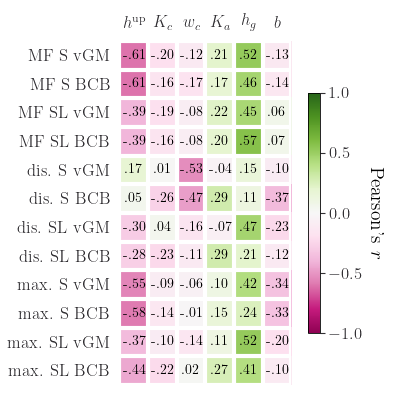

In [7]:
fig, ax = plt.subplots(figsize=(4, 4))

cmap="PiYG"
norm = colors.Normalize(vmin=-1, vmax=1)

lx = ['$h^\\mathrm{up}$', '$K_c$', '$w_c$', '$K_a$', '$h_g$', '$b$']
ly = ['MF S vGM', 'MF S BCB', 'MF SL vGM', 'MF SL BCB', 'dis. S vGM',
      'dis. S BCB', 'dis. SL vGM', 'dis. SL BCB', 'max. S vGM', 'max. S BCB',
      'max. SL vGM', 'max. SL BCB']

im = ax.imshow(data, cmap=cmap, norm=norm)
cbar = plt.colorbar(im, ax=ax, location='right', shrink=0.7,
                    ticks=[-1, -0.5, 0, 0.5, 1])
cbar.ax.set_ylabel('Pearson\'s $r$', rotation=-90, va="bottom")

ax.tick_params(top=True, bottom=False,
                   labeltop=True, labelbottom=False)

ax.spines[:].set_visible(False)
ax.set_xticks(np.arange(len(lx)), labels=lx)
ax.set_xticks(np.arange(len(lx)+1)-.5, minor=True)
ax.set_yticks(np.arange(len(ly)), labels=ly)
ax.set_yticks(np.arange(len(ly)+1)-.5, minor=True)
ax.grid(which="minor", color="w", linestyle='-', linewidth=3)
ax.tick_params(which="both", bottom=False, top=False,  left=False, right=False)

# Loop over data dimensions and create text annotations.
for i, j in product(range(len(ly)), range(len(lx))):
    text = ax.text(j, i, printR(data[i, j]), ha="center", va="center", 
                   color="k")

plt.tight_layout()
#plt.savefig(output_path / 'correlations.pdf')